In [2]:
import matplotlib.pyplot as plt
import random as r
import numpy as np

from pathlib import Path
from extractor import extract_mel_spectrogram

ROOT = Path.cwd()

## Single Mel Spectrogram

In [3]:
while not (ROOT / "datasets").exists():
    ROOT = ROOT.parent
dataset_path = ROOT / "datasets" / "fma" / "fma_large"
audio_files = list(dataset_path.rglob("*.mp3"))
print(f"Total Files Found : {len(audio_files)}")

Total Files Found : 106574


In [4]:
audio_path = r.choice(audio_files)

In [5]:
mel = extract_mel_spectrogram(audio_path)

In [6]:
print(mel.shape)

(128, 1293)


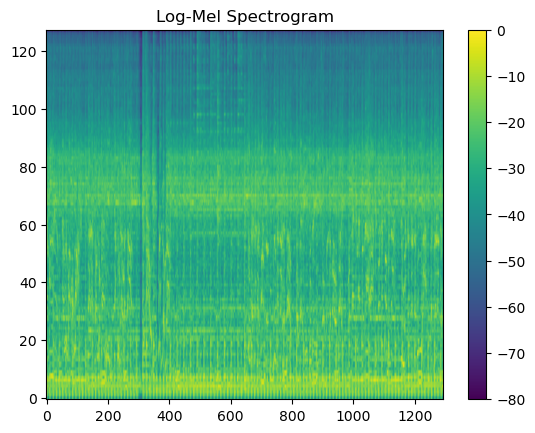

In [7]:
plt.imshow(mel, aspect="auto", origin="lower")
plt.colorbar()
plt.title("Log-Mel Spectrogram")
plt.show()

In [8]:
def slice_melspec(spec, token_width=45, stride=15):
    T = spec.shape[1]
    tokens = [
        np.pad(
            spec[:, i:i+token_width],
            ((0, 0), (0, max(0, token_width - spec[:, i:i+token_width].shape[1]))),
            mode='constant'
        )
        for i in range(0, T, stride)
    ]

    return tokens

In [9]:
tokens = slice_melspec(mel, token_width=45, stride=15)
print(f"Number of tokens: {len(tokens)}")
print(f"Single token shape: {tokens[0].shape}")

Number of tokens: 87
Single token shape: (128, 45)


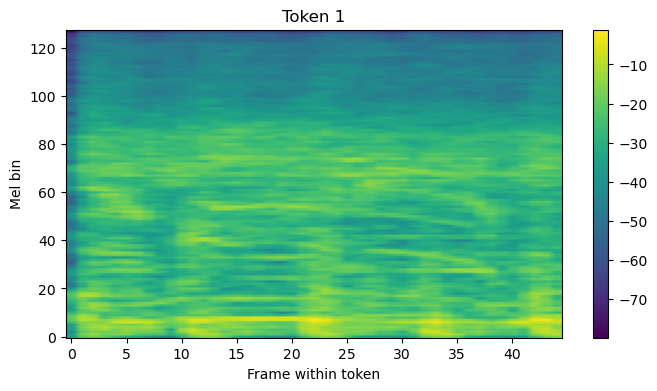

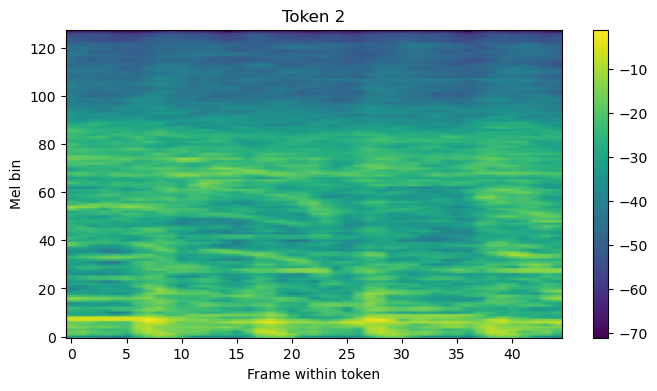

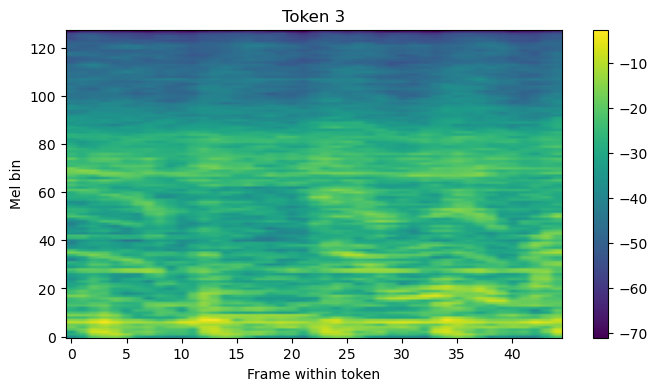

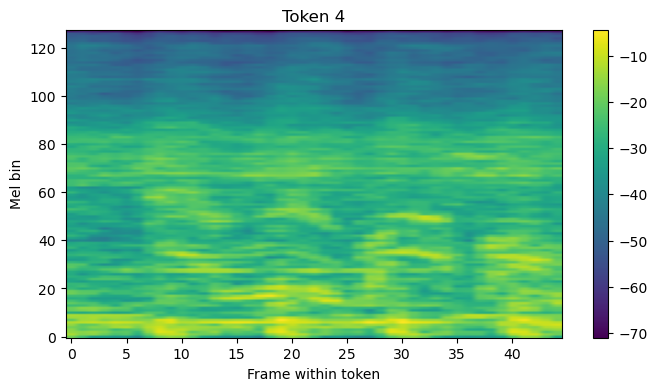

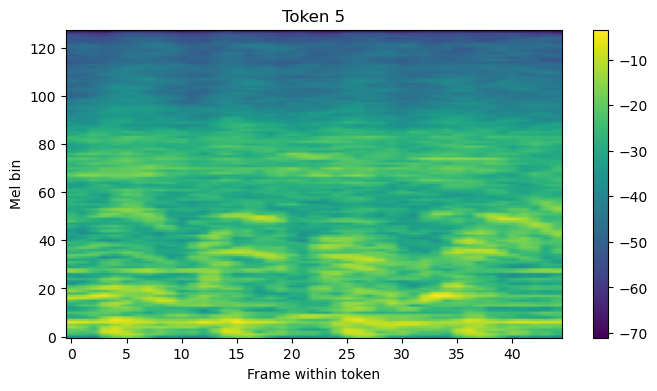

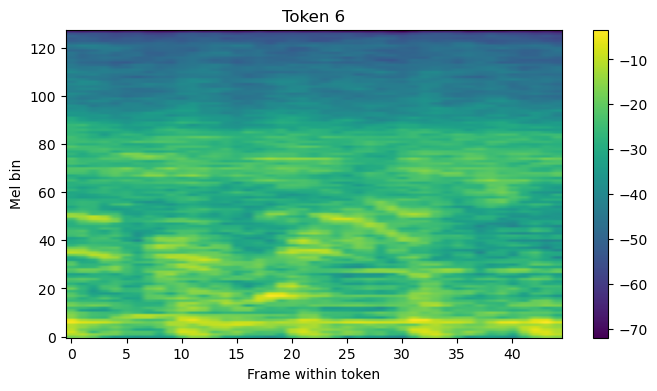

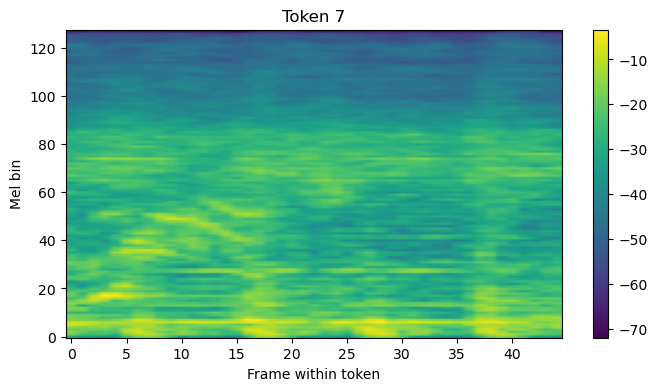

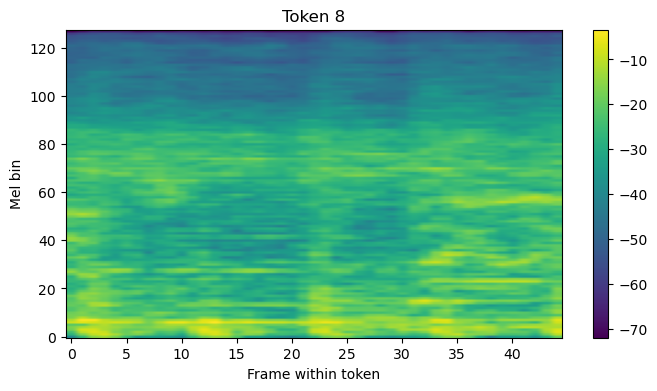

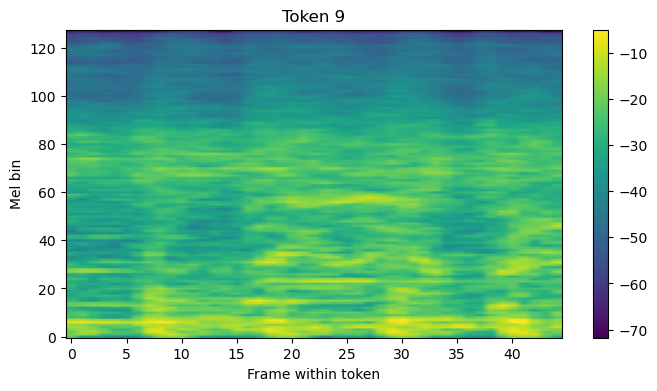

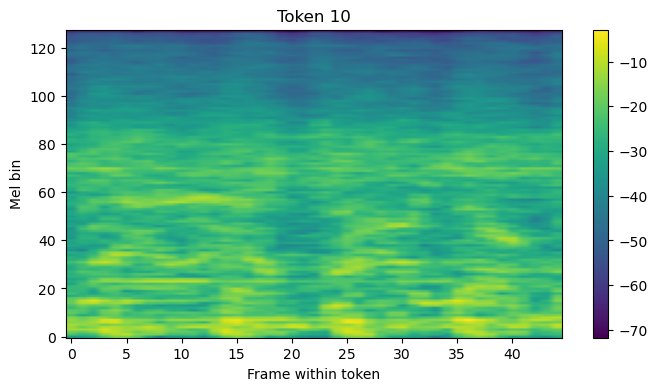

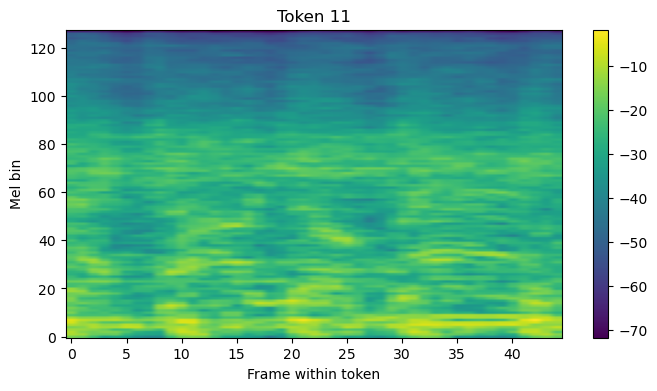

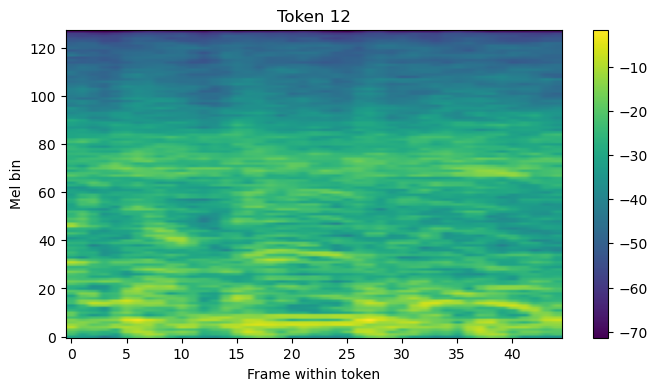

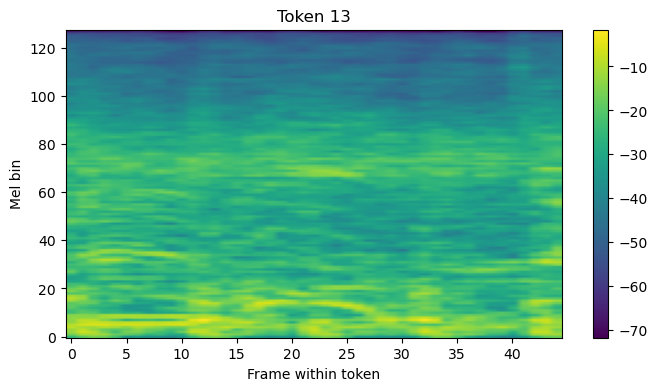

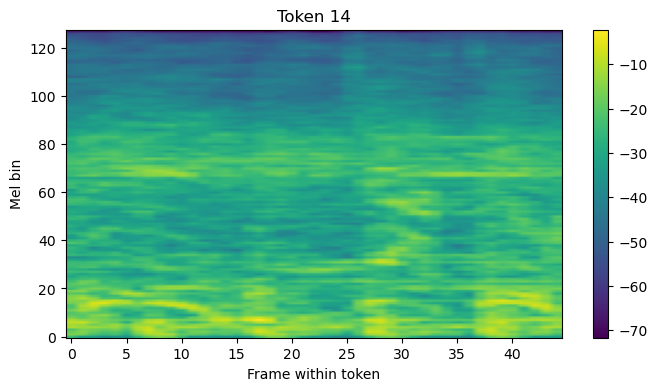

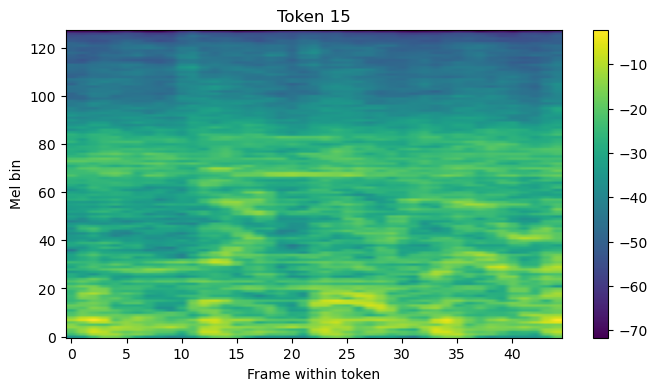

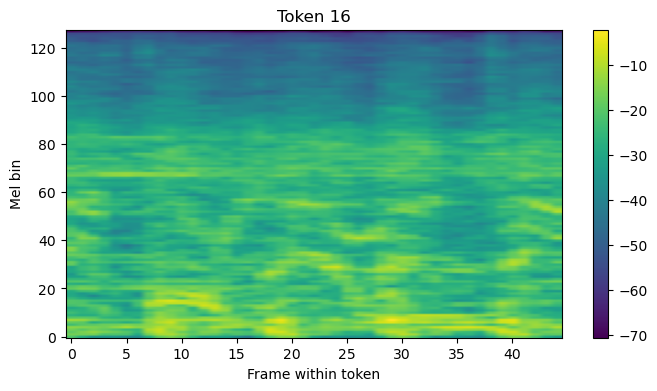

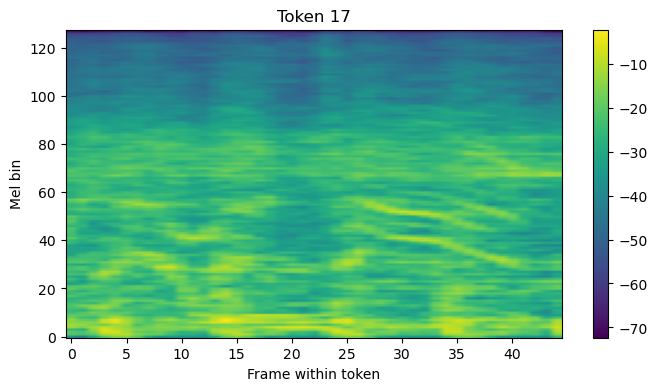

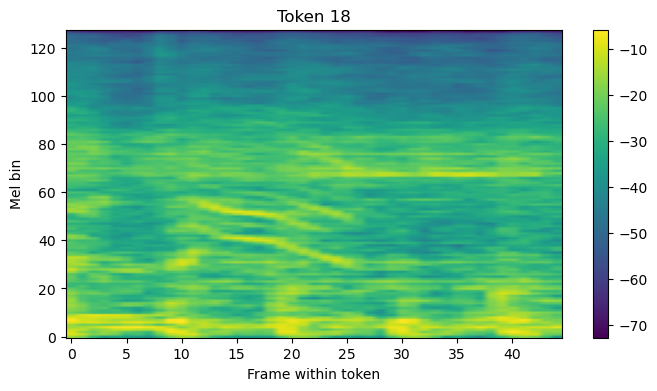

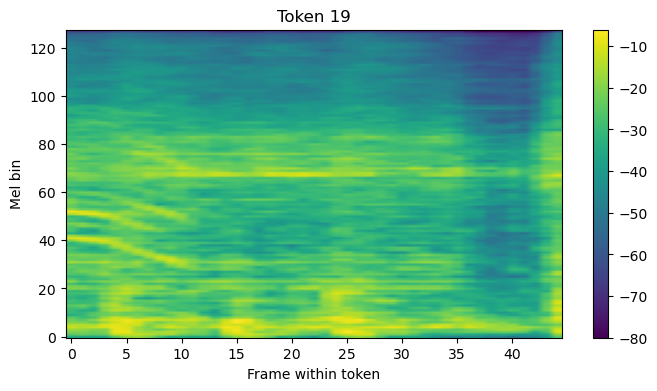

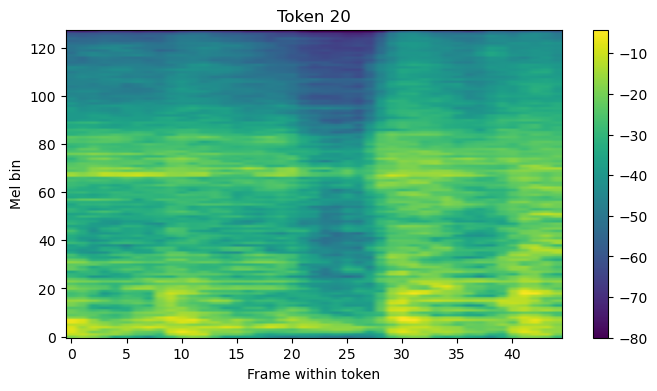

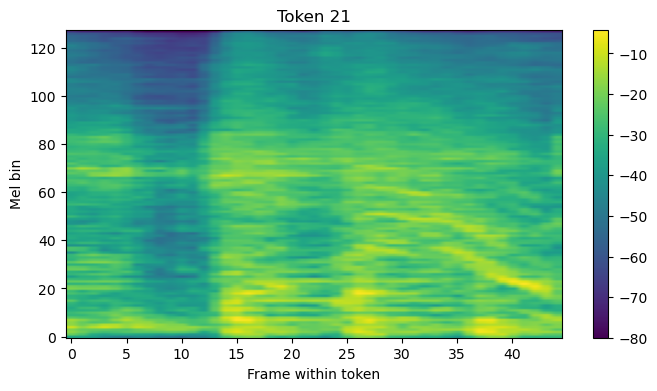

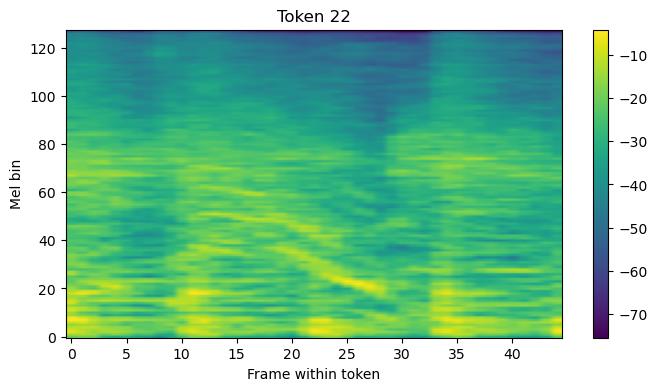

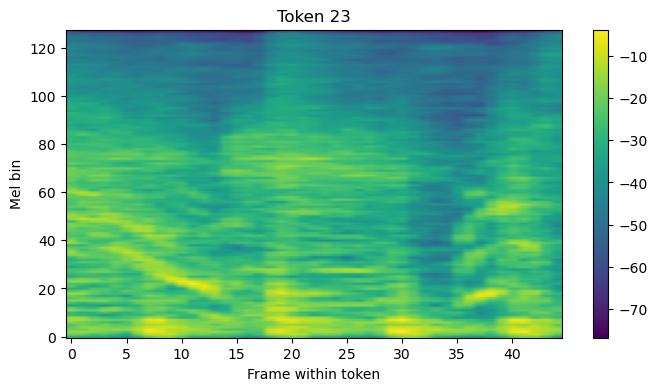

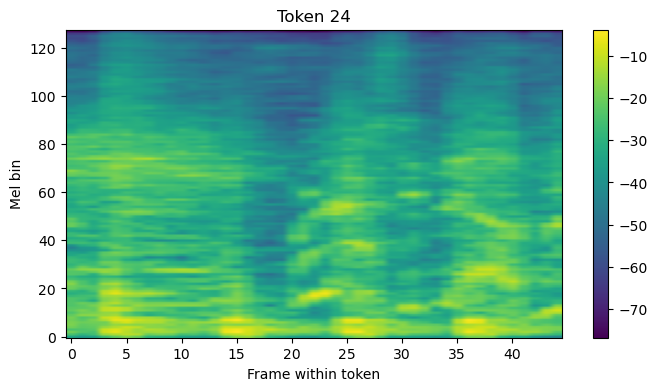

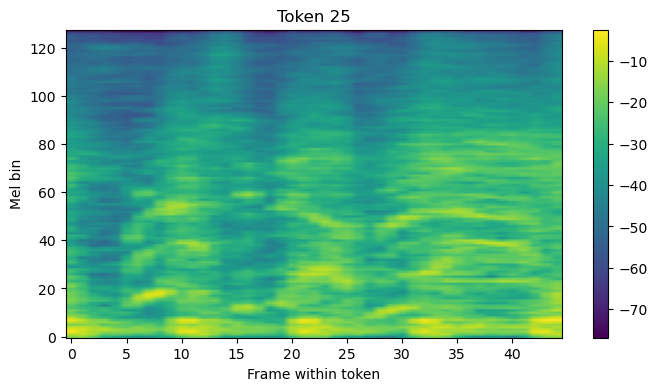

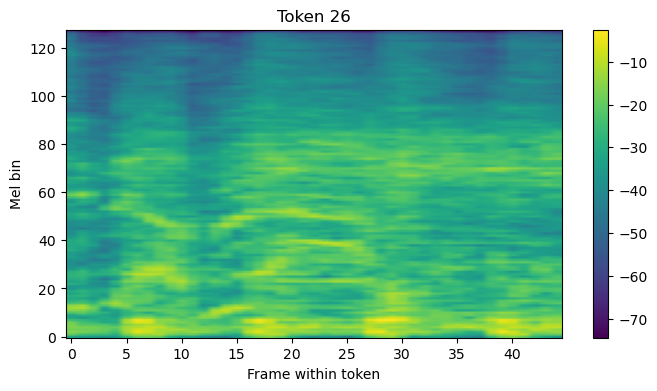

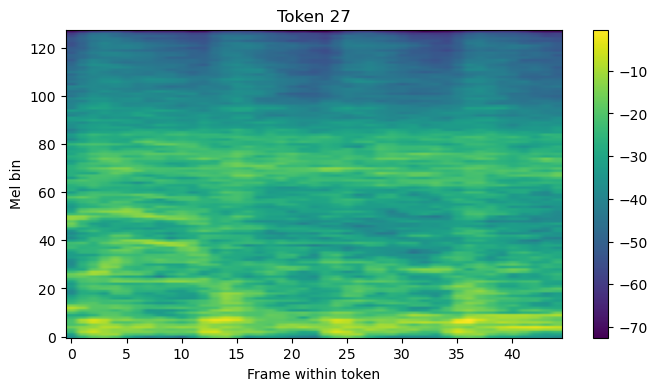

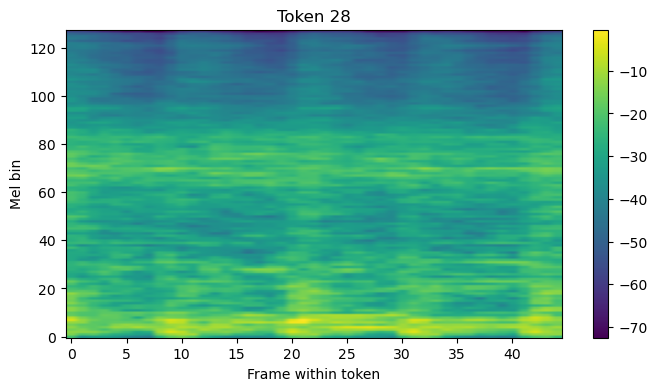

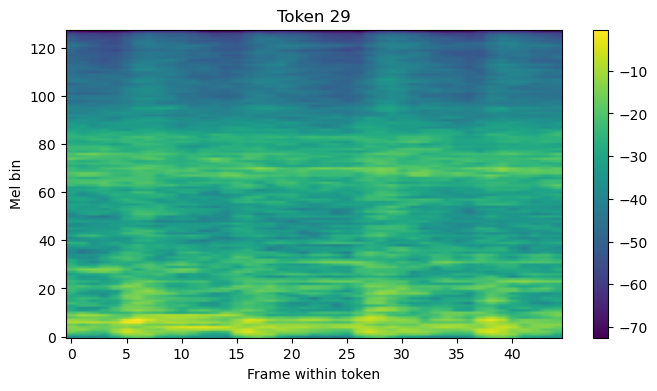

In [10]:
for idx in range(29):
    plt.figure(figsize=(8, 4))
    plt.imshow(tokens[idx], aspect="auto", origin="lower")
    plt.colorbar()
    plt.title(f"Token {idx + 1}")
    plt.xlabel("Frame within token")
    plt.ylabel("Mel bin")
    plt.show()

In [11]:
def token_stats(token):
    return {
        "mean": np.mean(token),
        "std": np.std(token),
        "max": np.max(token),
        "min": np.min(token),
    }

In [12]:
for i in tokens:
    print(token_stats(i))

{'mean': -31.433626, 'std': 11.072926, 'max': -1.1144485, 'min': -79.930664}
{'mean': -31.437077, 'std': 10.84253, 'max': -1.1144485, 'min': -70.999504}
{'mean': -31.367733, 'std': 10.993014, 'max': -2.5488014, 'min': -71.042984}
{'mean': -30.868364, 'std': 11.021909, 'max': -4.3465843, 'min': -71.042984}
{'mean': -30.573591, 'std': 11.173375, 'max': -3.4662209, 'min': -71.042984}
{'mean': -30.825132, 'std': 11.108408, 'max': -3.3648396, 'min': -72.01043}
{'mean': -31.717062, 'std': 11.013831, 'max': -3.3648396, 'min': -72.01043}
{'mean': -31.386778, 'std': 10.926992, 'max': -3.3648396, 'min': -72.01043}
{'mean': -31.071354, 'std': 10.9061, 'max': -4.9526024, 'min': -71.77133}
{'mean': -30.398668, 'std': 11.000659, 'max': -2.8696365, 'min': -71.77133}
{'mean': -30.510845, 'std': 11.116787, 'max': -1.6531334, 'min': -71.77133}
{'mean': -30.796995, 'std': 11.04536, 'max': -1.6531334, 'min': -71.366745}
{'mean': -31.016703, 'std': 10.85112, 'max': -1.6531334, 'min': -71.696976}
{'mean': -

In [13]:
def plot_hist(domain):
    plt.figure(figsize=(8, 5))
    plt.hist(domain, bins=20)
    plt.title("Distribution of Token Mean Energy")
    plt.xlabel("Mean dB")
    plt.ylabel("Frequency")
    plt.show()

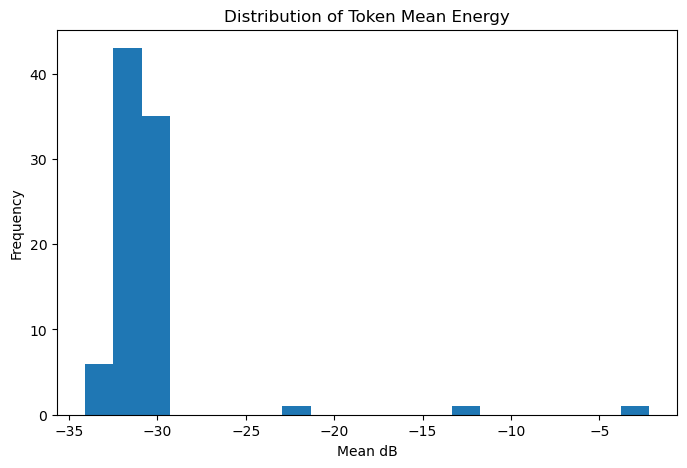

In [14]:
means = [np.mean(t) for t in tokens]
plot_hist(means)

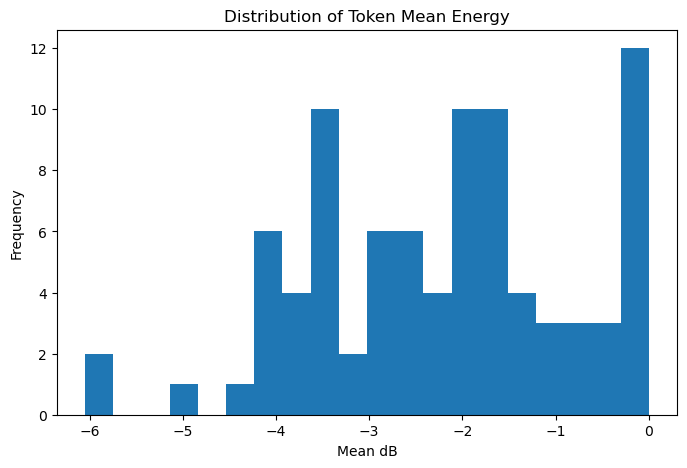

In [15]:
maxs = [np.max(t) for t in tokens]
plot_hist(maxs)

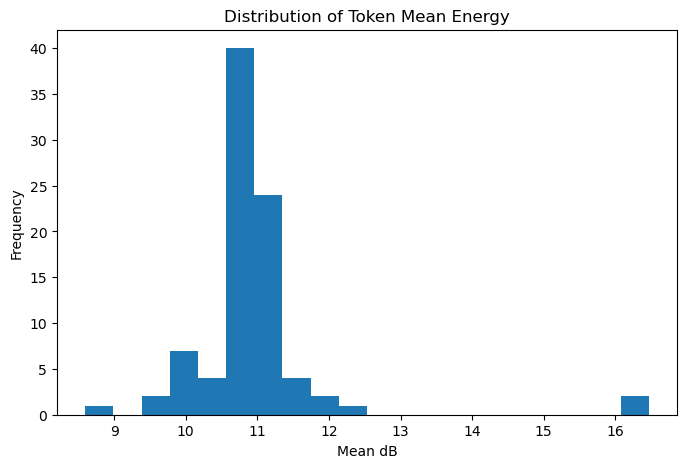

In [16]:
stds = [np.std(t) for t in tokens]
plot_hist(stds)

In [17]:
data = np.load("../../datasets/fma/mel_vad_dataset.npz", allow_pickle=True)

spectrograms = data["spectrograms"]
labels = data["labels"]
track_ids = data["track_ids"]
failed = data["failed"]

In [18]:
print("Total spectrograms:", len(spectrograms))
print("Total labels:", len(labels))
print("Total track_ids:", len(track_ids))
print("Total failed:", len(failed))

Total spectrograms: 27909
Total labels: 27909
Total track_ids: 27909
Total failed: 78665
